In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from analytics.db import query
from analytics.paths import FIGURES, RAW_WEB
from analytics.web import download


In [2]:
query("""
      --w12
      SELECT COUNT(*) AS orders_with_multiple_sellers
FROM (
    SELECT order_id
    FROM clean.order_items
    GROUP BY order_id
    HAVING COUNT(DISTINCT seller_id) > 1
) AS multi_seller_orders;
      """)


,orders_with_multiple_sellers
0,1278


## Part 0 — One Number for Many Orders

In [3]:

orders = query("""
    SELECT c.customer_state AS state,
           o.order_purchase_timestamp AS purchased,
           o.order_delivered_customer_date AS delivered,
           o.order_estimated_delivery_date AS estimated
    FROM clean.orders AS o
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
""")

arrived = orders.dropna(subset=["delivered"])

arrived["days"] = (
    arrived["delivered"] - arrived["purchased"]
).dt.total_seconds() / 86400

days = arrived["days"]

days.agg(["mean", "median", "max"]).round(2)


mean       12.56
median     10.22
max       209.63
Name: days, dtype: float64


### Delivery Time: Mean, Median and Maximum

We retrieved the order purchase and delivery timestamps from PostgreSQL and calculated the actual delivery duration in days. Orders without a delivery date were excluded because their delivery time cannot be calculated. The mean delivery time is 12.56 days, the median is 10.22 days, and the maximum delivery time is 209.63 days. The difference between the mean and median suggests that some unusually slow orders are pulling the average upward.


In [4]:

(days > 30).sum(), (days > 60).sum()


(np.int64(4553), np.int64(306))


### Identifying Slow Orders

We counted the orders that took more than 30 and 60 days to arrive. There were 4,553 orders taking more than 30 days and 306 orders taking more than 60 days. These unusually long delivery times create a long tail and increase the mean delivery time.


In [5]:
#0.a

share_over_mean = (days > days.mean()).mean() * 100

round(share_over_mean, 2)


np.float64(37.71)


### Exercise 0.a — Orders Above the Mean

We calculated the percentage of delivered orders that took longer than the mean delivery time. The share is below 50% because the distribution is right-skewed. A small number of extremely slow orders pull the mean upward, while the median is less affected by these extreme values.


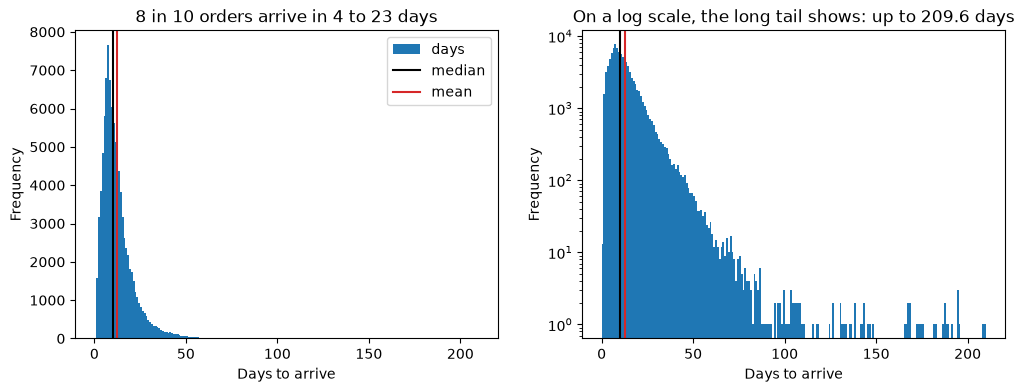

In [6]:

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

for ax, use_log in [(left, False), (right, True)]:
    days.plot(
        kind="hist",
        bins=range(0, 211),
        logy=use_log,
        ax=ax
    )
    ax.axvline(days.median(), color="black", label="median")
    ax.axvline(days.mean(), color="tab:red", label="mean")
    ax.set_xlabel("Days to arrive")

left.set_title("8 in 10 orders arrive in 4 to 23 days")
left.legend()

right.set_title("On a log scale, the long tail shows: up to 209.6 days")

fig.savefig(FIGURES / "day-12-days.png", bbox_inches="tight")

plt.show()



### Delivery Days Distribution

The first histogram shows that most orders are concentrated within a relatively short delivery period, while a small number of orders take much longer to arrive. The second histogram uses a logarithmic y-axis, making the low-frequency values in the long tail easier to see. The distribution is right-skewed, with delivery times extending up to approximately 209.6 days.


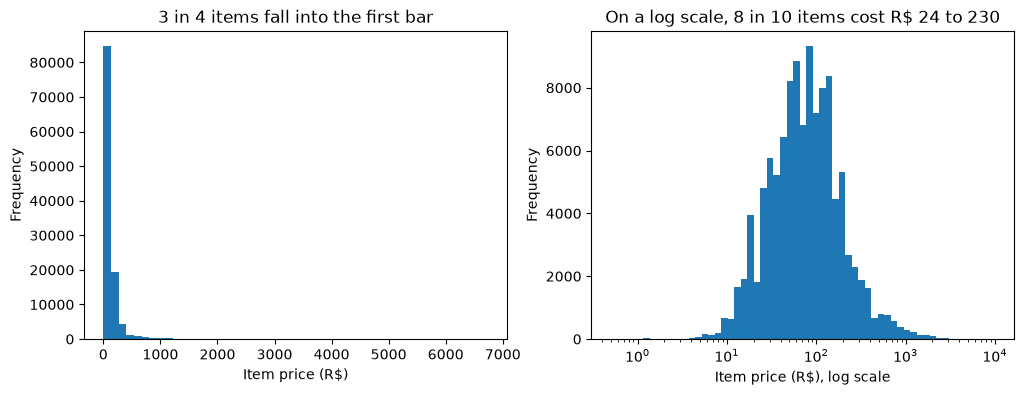

In [7]:

prices = query("SELECT price FROM clean.order_items")["price"]

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

prices.plot(kind="hist", bins=50, ax=left)

left.set_title("3 in 4 items fall into the first bar")
left.set_xlabel("Item price (R$)")

prices.plot(
    kind="hist",
    bins=np.geomspace(0.5, 10000, 60),
    logx=True,
    ax=right
)

right.set_title("On a log scale, 8 in 10 items cost R$ 24 to 230")
right.set_xlabel("Item price (R$), log scale")

fig.savefig(FIGURES / "day-12-prices.png", bbox_inches="tight")

plt.show()



### Item Price Distribution

The linear histogram shows that most items are concentrated in the first price range, which contains 84,833 out of 112,650 items. The second histogram uses logarithmic bins and a logarithmic x-axis to reveal more detail across the wide range of prices. Approximately 80% of items cost between R$ 24 and R$ 230.


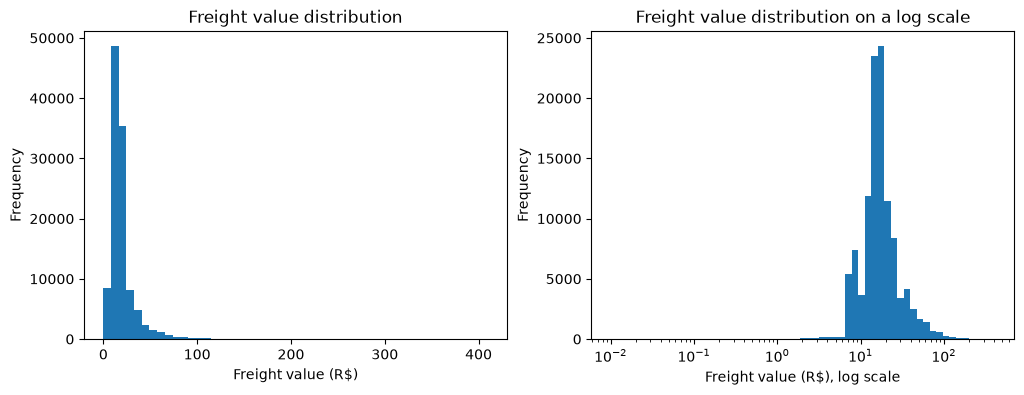

In [8]:
#1.a

freight = query("SELECT freight_value FROM clean.order_items")["freight_value"]

freight_positive = freight[freight > 0]

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

freight.plot(kind="hist", bins=50, ax=left)

left.set_title("Freight value distribution")
left.set_xlabel("Freight value (R$)")

freight_positive.plot(
    kind="hist",
    bins=np.geomspace(freight_positive.min(), freight_positive.max(), 60),
    logx=True,
    ax=right
)

right.set_title("Freight value distribution on a log scale")
right.set_xlabel("Freight value (R$), log scale")

plt.show()



### Exercise 1.a — Freight Value Distribution

We plotted the freight values using a linear histogram and a logarithmic x-axis. The logarithmic scale helps reveal the distribution across different freight values. The distribution is right-skewed if most items have relatively low shipping costs while a smaller number have much higher costs.


## Part 2 — Percentiles: P50, P90 and P99

In [9]:
eleven = pd.Series([2, 3, 4, 5, 5, 6, 7, 8, 9, 12, 30])

eleven.quantile([0.5, 0.9])

0.5     6.0
0.9    12.0
dtype: float64

### Understanding Percentiles with a Small Dataset

We created a small dataset containing 11 delivery times and used the quantile() function to calculate the 50th and 90th percentiles. P50 is 6 days, which represents the median, while P90 is 12 days, meaning that 90% of the values are at or below 12 days.

In [10]:
days.quantile([0.5, 0.9, 0.99]).round(1)

0.50    10.2
0.90    23.1
0.99    46.0
Name: days, dtype: float64

### Delivery Time Percentiles

We calculated the P50, P90 and P99 of the delivery times. P50 is 10.2 days, meaning that 50% of orders arrive within this time. P90 is 23.1 days, meaning that 90% arrive within this time, while P99 is 46 days, meaning that 99% arrive within this time. These percentiles help describe both typical and unusually slow deliveries.

In [11]:
prices.quantile([0.5, 0.9, 0.99]).round(2)

0.50     74.99
0.90    229.80
0.99    890.00
Name: price, dtype: float64

### Item Price Percentiles

We calculated the P50, P90 and P99 of the item prices. The median price is R$ 74.99, while 90% of items cost R$ 229.80 or less. The P99 is R$ 890.00, meaning that 99% of items are priced at or below this amount. These values show how prices are distributed across the dataset.

In [12]:
by_state = arrived.groupby("state")["days"].agg(
    orders="size",
    mean="mean",
    median="median",
    p90=lambda values: values.quantile(0.9),
).round(1)

by_state.loc[["SP", "MG", "RJ", "AM"]]

,orders,mean,median,p90
state,,,,
SP,40495,8.8,7.2,15.8
MG,11355,12.0,10.3,20.2
RJ,12353,15.3,12.0,29.1
AM,145,26.4,25.9,39.1


### Delivery Time by State

We grouped the delivered orders by customer state and calculated the order count, mean, median and P90 of delivery times. São Paulo (SP) has relatively short delivery times, while Amazonas (AM) has much longer delivery times. Minas Gerais (MG) and Rio de Janeiro (RJ) have relatively close medians, but RJ has a higher P90 of 29.1 days compared with 20.2 days in MG, indicating slower delivery times among its slowest orders.

In [13]:
#2.a
p90_to_median = (by_state["p90"] / by_state["median"]).round(2)

p90_to_median.sort_values(ascending=False)
p90_to_median.idxmax(), p90_to_median.max()

('RJ', np.float64(2.43))

### Exercise 2.a — P90 Compared with the Median

We calculated the ratio between P90 and the median for every state by dividing the P90 value by the median. We then sorted the ratios in descending order to identify the state with the largest relative difference between typical and slower deliveries. A higher ratio indicates that P90 is much larger compared with the median.

In [14]:
#2.b
arrived["promised_days"] = (
    (arrived["estimated"] - arrived["purchased"])
    .dt.total_seconds() / 86400
)

mean_promise = arrived.groupby("state")["promised_days"].mean().round(1)

by_state["mean_promise"] = mean_promise

by_state[["mean_promise", "p90"]]


,mean_promise,p90
state,,
AC,41.1,31.1
AL,32.6,39.4
AM,45.3,39.1
AP,46.2,34.7
BA,29.4,31.8
CE,31.4,34.7
DF,24.3,21.6
ES,25.6,25.3
GO,27.1,24.8


In [15]:
#2.b
(by_state["mean_promise"] > by_state["p90"]).sum()

np.int64(15)

### Exercise 2.b — Promised Delivery Time vs P90

We compared the mean promised delivery time with the actual delivery P90 for each state. Using a Boolean condition, we identified the states where the mean promised duration is greater than the P90. We summed the resulting True values to count how many states meet this condition.

### Calculating Promised Delivery Days

We calculated the promised delivery duration by subtracting the purchase timestamp from the estimated delivery timestamp and converting the result into days. We then grouped the promised delivery durations by customer state and calculated their mean. Finally, we added the mean promised delivery time to the by_state DataFrame for comparison with the actual delivery P90.

## Part 3 — Spread in one number

In [16]:

three = pd.Series([4, 6, 8])

three.var(), three.std()


(np.float64(4.0), np.float64(2.0))


### Understanding Variance and Standard Deviation

We created a small dataset containing three values: 4, 6 and 8. We used Pandas var() to calculate the variance and std() to calculate the standard deviation. The results are 4.0 and 2.0, respectively. Pandas uses the sample calculation by default, dividing the sum of squared deviations by the number of observations minus one.


In [17]:

round(days.std(), 2), round(days.var(), 2)


(np.float64(9.55), np.float64(91.14))


### Standard Deviation of Delivery Times

The standard deviation of delivery times is 9.55 days, while the variance is 91.14 days squared. The standard deviation is easier to interpret because it uses the same unit as the original delivery data. It measures how spread out the delivery times are around their mean.



In [18]:

low = days.mean() - 2 * days.std()

high = days.mean() + 2 * days.std()

round(low, 2), round(high, 2), (days < low).sum(), (days > high).sum()


(np.float64(-6.53), np.float64(31.65), np.int64(0), np.int64(3878))


### The Two-Standard-Deviation Window

We calculated a window from the mean minus two standard deviations to the mean plus two standard deviations. The lower limit is -6.53 days and the upper limit is 31.65 days. There are no orders below the lower limit, but 3,878 orders are above the upper limit. This shows that the delivery-time distribution is strongly right-skewed, so the symmetric window does not describe the data well.


In [19]:

usual = days[days <= 60]

round(usual.std(), 2), round(usual.median(), 2)


(np.float64(8.37), np.float64(10.2))


### Effect of Extreme Delivery Times

We removed the 306 orders that took more than 60 days to arrive and recalculated the standard deviation and median. The standard deviation decreased from 9.55 to 8.37 days, while the median changed only slightly from 10.22 to 10.20 days. This demonstrates that the standard deviation is more sensitive to extreme values than the median.


In [20]:
#3.a

price_low = prices.mean() - 2 * prices.std()

price_high = prices.mean() + 2 * prices.std()

round(price_low, 2), round(price_high, 2), (prices < price_low).sum(), (prices > price_high).sum()



(np.float64(-246.61), np.float64(487.92), np.int64(0), np.int64(3494))


### Exercise 3.a — Standard Deviation of Item Prices

We calculated a two-standard-deviation window for item prices using the mean and standard deviation. We then counted the items below the lower limit and above the upper limit. The results show how the price distribution differs from a symmetric bell-shaped distribution, especially when extreme prices are present.


## Part 4 — Box plots: compare spreads

In [21]:

eleven.quantile([0.25, 0.75])


0.25    4.5
0.75    8.5
dtype: float64


### Understanding Quartiles

We calculated the 25th and 75th percentiles of the eleven delivery times. P25 is 4.5 days and P75 is 8.5 days. These values define the lower and upper boundaries of the box in a box plot, containing the middle 50% of the observations.


In [22]:

six_states = ["SP", "MG", "RJ", "BA", "CE", "AM"]

six = arrived[arrived["state"].isin(six_states)]



### Selecting Six Brazilian States

We created a list containing six Brazilian state codes: SP, MG, RJ, BA, CE and AM. We used the isin() method to filter the arrived DataFrame, keeping only orders belonging to these six states. The resulting DataFrame is stored in six.


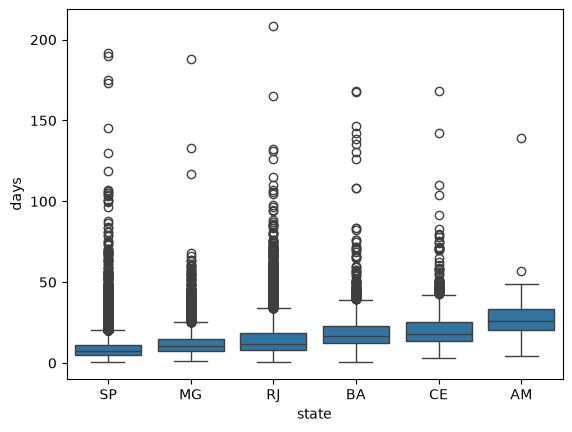

In [23]:

ax = sns.boxplot(
    data=six,
    x="state",
    y="days",
    order=six_states
)

plt.show()



### Box Plot of Delivery Times Across Six States

We created a box plot using Seaborn to compare delivery-time distributions across six Brazilian states. The x-axis represents the customer state, while the y-axis represents delivery days. Each box shows the median, middle 50% of delivery times, whiskers and outliers.


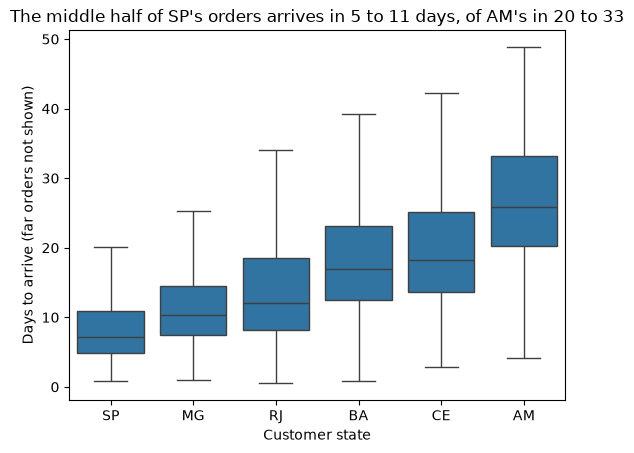

In [24]:

ax = sns.boxplot(
    data=six,
    x="state",
    y="days",
    order=six_states,
    showfliers=False
)

ax.set_title("The middle half of SP's orders arrives in 5 to 11 days, of AM's in 20 to 33")
ax.set_xlabel("Customer state")
ax.set_ylabel("Days to arrive (far orders not shown)")

ax.figure.savefig(FIGURES / "day-12-states.png", bbox_inches="tight")

plt.show()



### Comparing State Distributions Without Outliers

We created a second box plot using showfliers=False to hide extreme values from the visualization. The original data remains unchanged. Hiding the outliers makes it easier to compare the medians and middle 50% of delivery times across the six states. The chart also clearly indicates that far orders are not shown.


In [25]:
#4.a

category_prices = query("""
    WITH top_categories AS (
        SELECT
            p.product_category_name AS category,
            COUNT(*) AS item_count
        FROM clean.products AS p
        JOIN clean.order_items AS oi
            ON oi.product_id = p.product_id
        WHERE p.product_category_name IS NOT NULL
        GROUP BY p.product_category_name
        ORDER BY item_count DESC
        LIMIT 5
    )
    SELECT
        tc.category,
        tc.item_count,
        oi.price
    FROM top_categories AS tc
    JOIN clean.products AS p
        ON p.product_category_name = tc.category
    JOIN clean.order_items AS oi
        ON oi.product_id = p.product_id
    ORDER BY tc.item_count DESC
""")

category_prices.head()


,category,item_count,price
0,cama_mesa_banho,11115,249.90
1,cama_mesa_banho,11115,205.00
2,cama_mesa_banho,11115,45.90
3,cama_mesa_banho,11115,114.90
4,cama_mesa_banho,11115,95.03


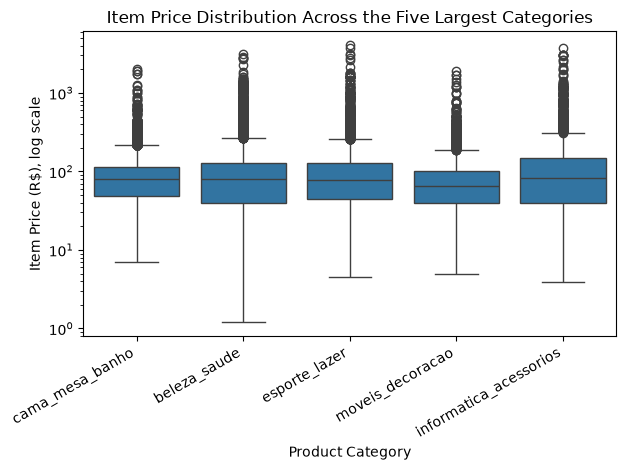

In [26]:
#4.a

category_order = (
    category_prices[["category", "item_count"]]
    .drop_duplicates()
    .sort_values("item_count", ascending=False)["category"]
    .tolist()
)

ax = sns.boxplot(
    data=category_prices,
    x="category",
    y="price",
    order=category_order
)

ax.set_yscale("log")

ax.set_title("Item Price Distribution Across the Five Largest Categories")
ax.set_xlabel("Product Category")
ax.set_ylabel("Item Price (R$), log scale")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.show()



### Box Plot of Item Prices by Product Category

We created a box plot to compare item prices across the five categories with the highest item counts. We used a logarithmic y-axis to make price distributions easier to compare across a wide range of values. Each box represents the middle 50% of prices within its category, and its central line represents the median.



## Part 5 — Same numbers, different data

In [27]:

ANSCOMBE_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/anscombe.csv"

anscombe_path = RAW_WEB / "seaborn" / "anscombe.csv"

download(anscombe_path, ANSCOMBE_URL)

anscombe = pd.read_csv(anscombe_path)

anscombe.shape


(44, 3)


### Downloading the Anscombe Dataset

We downloaded the Anscombe dataset from the Seaborn sample data repository using the project's download utility. We then loaded the CSV file into a Pandas DataFrame using read_csv(). The dataset contains 44 rows and 3 columns: dataset, x and y, with 11 observations in each of the four datasets.


In [28]:

anscombe.groupby("dataset").agg(
    x_mean=("x", "mean"),
    y_mean=("y", "mean"),
    x_std=("x", "std"),
    y_std=("y", "std"),
).round(2)


,x_mean,y_mean,x_std,y_std
dataset,,,,
I,9.0,7.5,3.32,2.03
II,9.0,7.5,3.32,2.03
III,9.0,7.5,3.32,2.03
IV,9.0,7.5,3.32,2.03



### Summary Statistics of the Four Datasets

We grouped the Anscombe data by dataset and calculated the mean and standard deviation for both x and y. All four datasets have the same summary statistics: x_mean is 9.0, y_mean is 7.5, x_std is 3.32 and y_std is 2.03. However, these numbers alone do not reveal the actual shapes or patterns of the datasets.


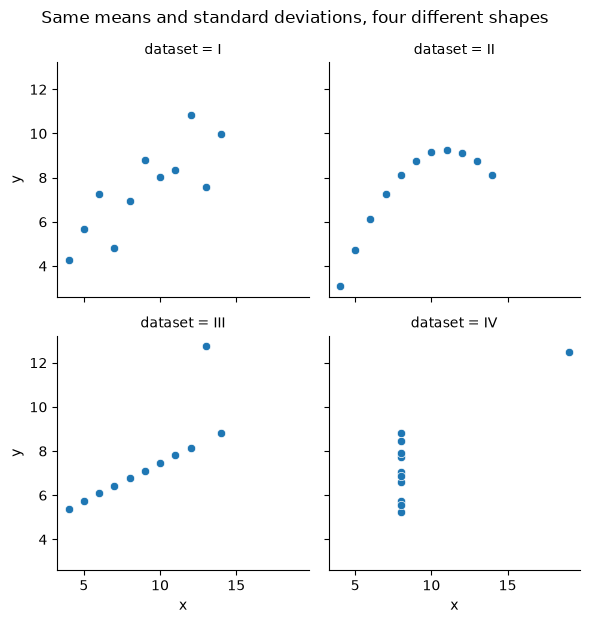

In [29]:

grid = sns.relplot(
    data=anscombe,
    x="x",
    y="y",
    col="dataset",
    col_wrap=2,
    height=3
)

grid.figure.suptitle(
    "Same means and standard deviations, four different shapes",
    y=1.03
)

grid.savefig(FIGURES / "day-12-anscombe.png")

plt.show()



### Visualizing the Four Datasets

We created four scatter plots using Seaborn's relplot(), separating the observations by dataset. Dataset I follows a roughly linear pattern, Dataset II forms a curve, Dataset III contains a linear pattern with one extreme point, and Dataset IV has nearly all x-values concentrated at 8 except for one observation. Although all four datasets have the same means and standard deviations, their visual patterns are very different.


In [30]:
#a.5

third = anscombe[anscombe["dataset"] == "III"]

outlier_index = third["y"].idxmax()

third_without_outlier = third.drop(index=outlier_index)

third_without_outlier["y"].agg(["mean", "std"]).round(2)


mean    6.98
std     1.11
Name: y, dtype: float64


### Exercise 5.a — Effect of One Extreme Point

We selected Dataset III and removed the observation with the largest y-value. After removing this point, the mean of y decreased from 7.50 to 6.98, while the standard deviation decreased from 2.03 to 1.11. This demonstrates how a single extreme observation can significantly affect summary statistics.

